In [ ]:
#@title Cell 0: Initialize Environment and Install Dependencies
from google.colab import drive
import os
import subprocess
import shutil
from huggingface_hub import hf_hub_download, snapshot_download

drive.mount('/content/drive')
PROJECT_ROOT = "/content/drive/MyDrive/CSU-EI-colab"
os.makedirs(PROJECT_ROOT, exist_ok=True)
os.chdir(PROJECT_ROOT)
print("Current working directory:", os.getcwd())

# Clone GitHub repository
REPO_URL = "https://github.com/crxcsu/CSU-EI.git"
if not os.path.exists(".git"):
    print("Cloning CSU-EI from GitHub...")
    !git clone {REPO_URL} {PROJECT_ROOT}
else:
    print("Repo exists, pull latest code...")
    !git pull
print("Files in directory:", os.listdir("."))

# Detect CUDA version tag
out = subprocess.run(["nvcc", "--version"], capture_output=True, text=True).stdout
if "release 13.0" in out:
    cuda_tag = "cu130"
elif "release 12.6" in out:
    cuda_tag = "cu126"
elif "release 12.4" in out:
    cuda_tag = "cu124"
elif "release 12.1" in out:
    cuda_tag = "cu121"
else:
    raise RuntimeError("CUDA not found or unsupported, use GPU runtime")

# Install PyTorch stack
!pip install torch torchvision torchaudio --extra-index-url https://download.pytorch.org/whl/{cuda_tag}
# Install remaining dependencies
!pip install rdkit pandas numpy pyarrow gradio gradio_client hf-gradio fastapi uvicorn python-multipart pydantic httpx aiofiles ffmpy pydub transformers huggingface_hub tokenizers safetensors scipy matplotlib tqdm requests
!pip install -U "huggingface_hub>=0.23"

REPO_ID = "zzm-csu/CSUEI_database"
REPO_TYPE = "dataset"

# ---------------------- Local target paths ----------------------
local_json = os.path.join(PROJECT_ROOT, "data", "external_test_dataset", "nist23_external_test_smiles.json")
local_xianglansu_dir = os.path.join(PROJECT_ROOT, "data", "external_test_dataset", "xianglansu")
local_result_dir = os.path.join(PROJECT_ROOT, "results", "CSUEI_nist23_smil6_msl6_bs1024_DDP1_lr4.0e-04_smiesa1_msesa1_rm1_se1_2026-02-13_193603")

os.makedirs(os.path.dirname(local_json), exist_ok=True)
os.makedirs(local_xianglansu_dir, exist_ok=True)
os.makedirs(local_result_dir, exist_ok=True)

# 1. Download single json file
if not os.path.exists(local_json):
    tmp_json_dir = os.path.join(PROJECT_ROOT, "_tmp_json")
    os.makedirs(tmp_json_dir, exist_ok=True)
    hf_hub_download(
        repo_id=REPO_ID,
        repo_type=REPO_TYPE,
        filename="database/molecular_dataset/external_test_dataset/nist23_external_test_smiles.json",
        local_dir=tmp_json_dir,
        force_download=False,
    )
    src_json = os.path.join(
        tmp_json_dir,
        "database/molecular_dataset/external_test_dataset/nist23_external_test_smiles.json",
    )
    shutil.move(src_json, local_json)
    shutil.rmtree(tmp_json_dir)

# 2. Download xianglansu folder
tmp_xianglansu = os.path.join(PROJECT_ROOT, "_tmp_xianglansu")
if not any(os.listdir(local_xianglansu_dir)):
    snapshot_download(
        repo_id=REPO_ID,
        repo_type=REPO_TYPE,
        local_dir=tmp_xianglansu,
        allow_patterns=["database/molecular_dataset/external_test_dataset/xianglansu/**"],
        force_download=False,
    )
    src_dir = os.path.join(
        tmp_xianglansu,
        "database/molecular_dataset/external_test_dataset/xianglansu",
    )
    for f in os.listdir(src_dir):
        shutil.move(os.path.join(src_dir, f), local_xianglansu_dir)
    shutil.rmtree(tmp_xianglansu)

# 3. Download result folder
tmp_result = os.path.join(PROJECT_ROOT, "_tmp_result")
if not any(os.listdir(local_result_dir)):
    result_pattern = "results/CSUEI_nist23_smil6_msl6_bs1024_DDP1_lr4.0e-04_smiesa1_msesa1_rm1_se1_2026-02-13_193603/**"
    snapshot_download(
        repo_id=REPO_ID,
        repo_type=REPO_TYPE,
        local_dir=tmp_result,
        allow_patterns=[result_pattern],
        force_download=False,
    )
    src_result_dir = os.path.join(
        tmp_result,
        "results",
        "CSUEI_nist23_smil6_msl6_bs1024_DDP1_lr4.0e-04_smiesa1_msesa1_rm1_se1_2026-02-13_193603",
    )
    for f in os.listdir(src_result_dir):
        shutil.move(os.path.join(src_result_dir, f), local_result_dir)
    shutil.rmtree(tmp_result)

print("✅ Done, all files placed to target local paths.")


# 0. Preparation and Global Definition

In [1]:
import warnings, os
warnings.filterwarnings("ignore")
if os.getcwd().endswith('analyzer'):
    os.chdir(os.path.dirname(os.getcwd()))
import json
import torch
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from mpl_toolkits.axes_grid1 import make_axes_locatable
from rdkit import Chem
from rdkit.Chem import AllChem
from rdkit.Chem import Draw
from data_provider.dataset import process_ms_spectra_for_wcs
from analyzer.core import auto_eval_topk, get_data_and_features, get_cos_distance, get_topk_acc, find_functional_group_pairs, plot_mol_structure, plot_distance_curve

pd.set_option('display.unicode.east_asian_width', True)
pd.set_option('display.unicode.ambiguous_as_wide', True)
pd.set_option('display.max_colwidth', None)

config_path = "results/CSUEI_nist23_smil6_msl6_bs1024_DDP1_lr4.0e-04_smiesa1_msesa1_rm1_se1_2026-02-13_193603/config_2026-02-13_193603.json"


exp_dir = os.path.dirname(config_path)
time_stamp = '_'.join(exp_dir.split('_')[-2:])
# Define save directory
save_dir = os.path.join(exp_dir, "plot_result_analyzer")
os.makedirs(save_dir, exist_ok=True)
save_dir = None 

# 1. UMAP

In [2]:
import umap
with open("data/external_test_dataset/nist23_external_test_smiles.json", "r", encoding="utf-8") as f:
    data = json.load(f)
df = pd.DataFrame(list(data.values()))
test_data = (df["smiles"].values.tolist(), df["peaks"].values.tolist())

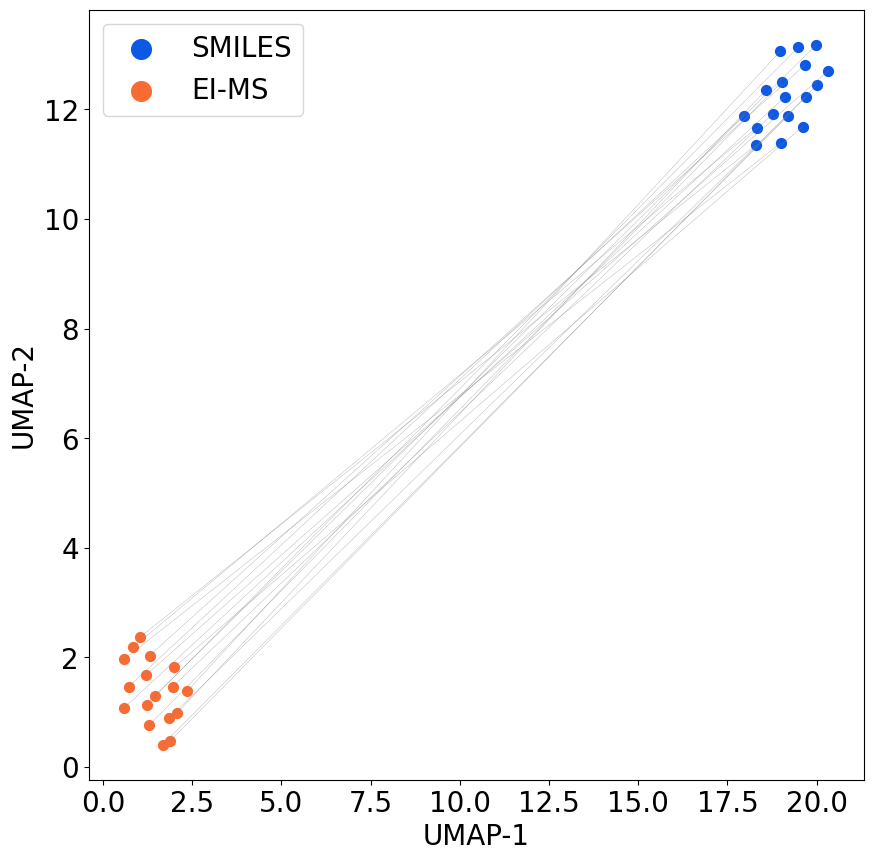

In [3]:
# Custom parameters
point_size = 50
legend_fontsize = 20
legend_markerscale = 2
line_color = "gray"
line_width = 0.25
line_alpha = 0.75

_, all_feature = get_data_and_features(
    config_path, test_data, batch_size=256, epoch=0
)
smiles_feature, ms_feature, similarity, _, _ = all_feature

feature = np.concatenate([
    smiles_feature.cpu().numpy(),
    ms_feature.cpu().numpy()
])
len1 = len(smiles_feature)
feature = umap.UMAP(n_components=2).fit_transform(feature)

fig, ax = plt.subplots(figsize=(10, 10))

# Connect paired SMILES and EI-MS points
for i in range(len1):
    ax.plot(
        [feature[i, 0], feature[len1 + i, 0]],
        [feature[i, 1], feature[len1 + i, 1]],
        color=line_color,
        linewidth=line_width,
        alpha=line_alpha
    )

ax.scatter(feature[:len1, 0], feature[:len1, 1],
           color="#0D59E4", label="SMILES", s=point_size)

ax.scatter(feature[len1:, 0], feature[len1:, 1],
           color="#F86B33", label="EI-MS", s=point_size)

ax.legend(fontsize=legend_fontsize, markerscale=legend_markerscale)
ax.set_xlabel("UMAP-1", fontsize=20)
ax.set_ylabel("UMAP-2", fontsize=20)
ax.tick_params(axis="both", labelsize=20)

if save_dir is not None:
    plt.savefig(os.path.join(save_dir, "UMAP_epoch0.svg"),
                bbox_inches="tight", pad_inches=0.02)

plt.show()

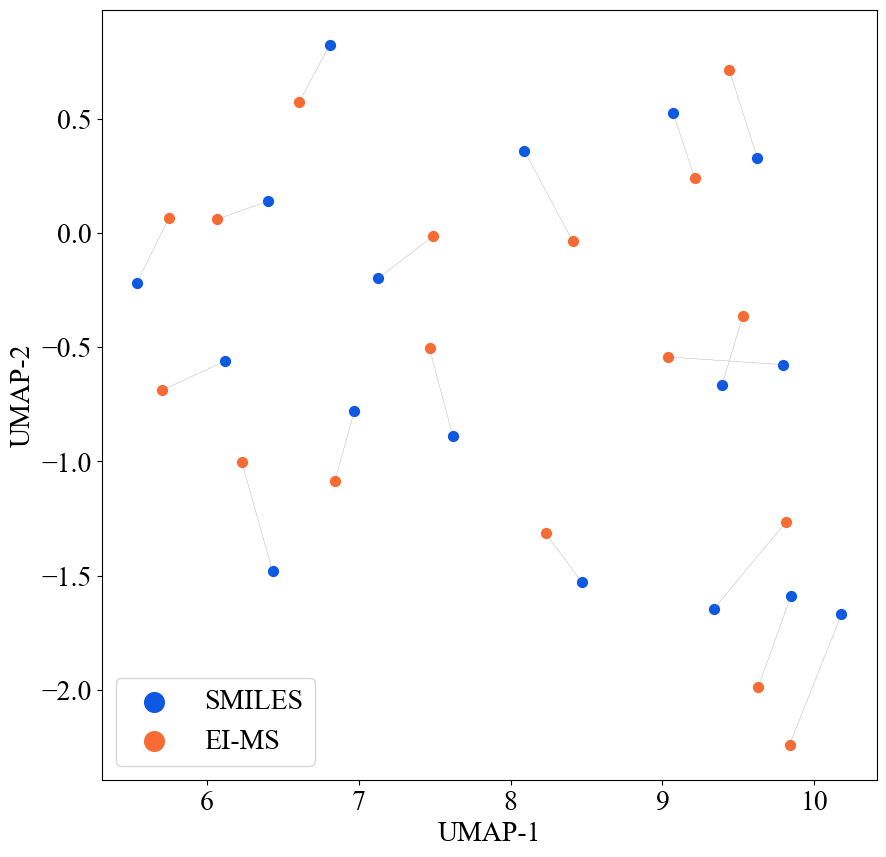

In [20]:
_, all_feature = get_data_and_features(
    config_path, test_data, batch_size=256, epoch=None
)
smiles_feature, ms_feature, similarity, _, _ = all_feature

feature = np.concatenate([
    smiles_feature.cpu().numpy(),
    ms_feature.cpu().numpy()
])
len1 = len(smiles_feature)
feature = umap.UMAP(n_components=2).fit_transform(feature)

fig, ax = plt.subplots(figsize=(10, 10))

# Connect paired SMILES and EI-MS points
for i in range(len1):
    ax.plot(
        [feature[i, 0], feature[len1 + i, 0]],
        [feature[i, 1], feature[len1 + i, 1]],
        color=line_color,
        linewidth=line_width,
        alpha=line_alpha
    )

ax.scatter(feature[:len1, 0], feature[:len1, 1],
           color="#0D59E4", label="SMILES", s=point_size)

ax.scatter(feature[len1:, 0], feature[len1:, 1],
           color="#F86B33", label="EI-MS", s=point_size)

ax.legend(fontsize=legend_fontsize, markerscale=legend_markerscale)
ax.set_xlabel("UMAP-1", fontsize=20)
ax.set_ylabel("UMAP-2", fontsize=20)
ax.tick_params(axis="both", labelsize=20)

if save_dir is not None:
    plt.savefig(os.path.join(save_dir, "UMAP_epoch100.svg"),
                bbox_inches="tight", pad_inches=0.02)

plt.show()

# 2. Calculating cosine similarity

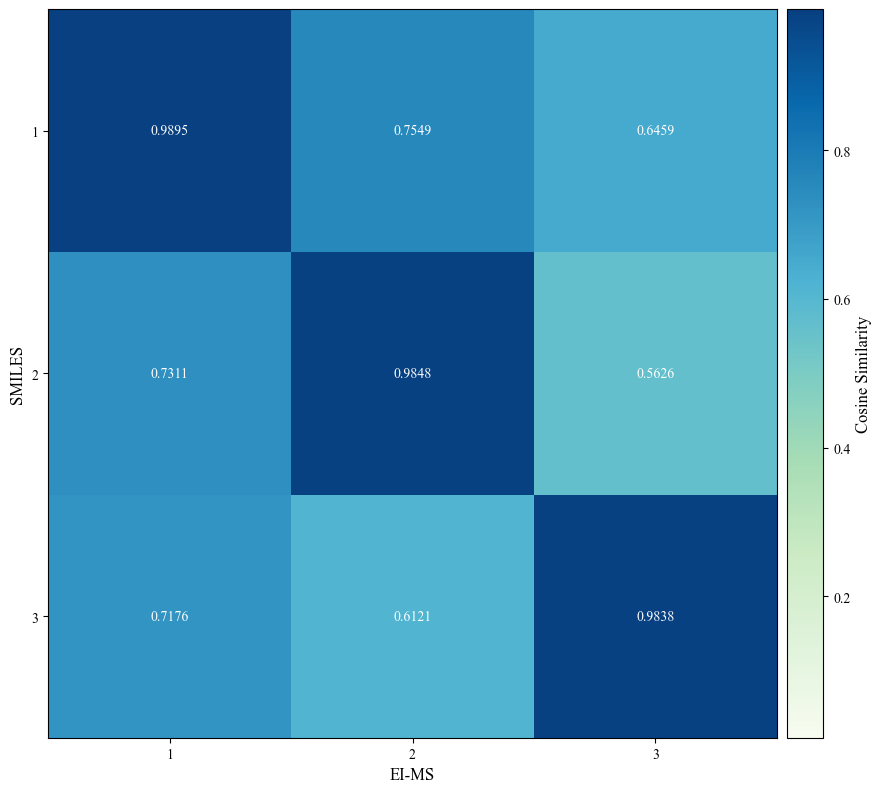

In [ ]:
with open("data/external_test_dataset/xianglansu/smiles_ms.json", 'r') as f:
    datas = json.loads(f.read())
SMILES = []
EIMS = []
for data in datas:
    EIMS.append(data["peaks"])
    SMILES.append(data["smiles"])
xianglansu_data = (SMILES, EIMS) 
_, all_feature = get_data_and_features(config_path, xianglansu_data, batch_size=1)
smiles_feature, ms_feature, similarity, _, _ = all_feature

fig, ax = plt.subplots(figsize=(10, 10))
im = ax.imshow(similarity, cmap='GnBu', interpolation='nearest')

norm = Normalize(vmin=0.01, vmax=0.99)
im = ax.imshow(similarity, cmap='GnBu', interpolation='nearest', norm=norm)

for i in range(similarity.shape[0]):
    for j in range(similarity.shape[1]):
        color = "white" if similarity[i, j] > 0.5 else "black"
        ax.text(j, i, np.round(similarity[i, j], 4), ha="center", va="center", color=color, fontsize=10)

ax.set_xticks(range(similarity.shape[1]))
ax.set_xticklabels(range(1, similarity.shape[1] + 1))
ax.set_yticks(range(similarity.shape[0]))
ax.set_yticklabels(range(1, similarity.shape[0] + 1))

divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="5%", pad=0.1)
cbar = fig.colorbar(im, cax=cax)
cbar.set_label('Cosine Similarity', fontsize=12)

ax.set_xlabel('EI-MS', fontsize=12)
ax.set_ylabel('SMILES', fontsize=12)

if save_dir is not None:
    save_path = os.path.join(save_dir, 'xianglansu_similarity.svg')
    plt.savefig(save_path, bbox_inches="tight", pad_inches=0.02)
plt.show()

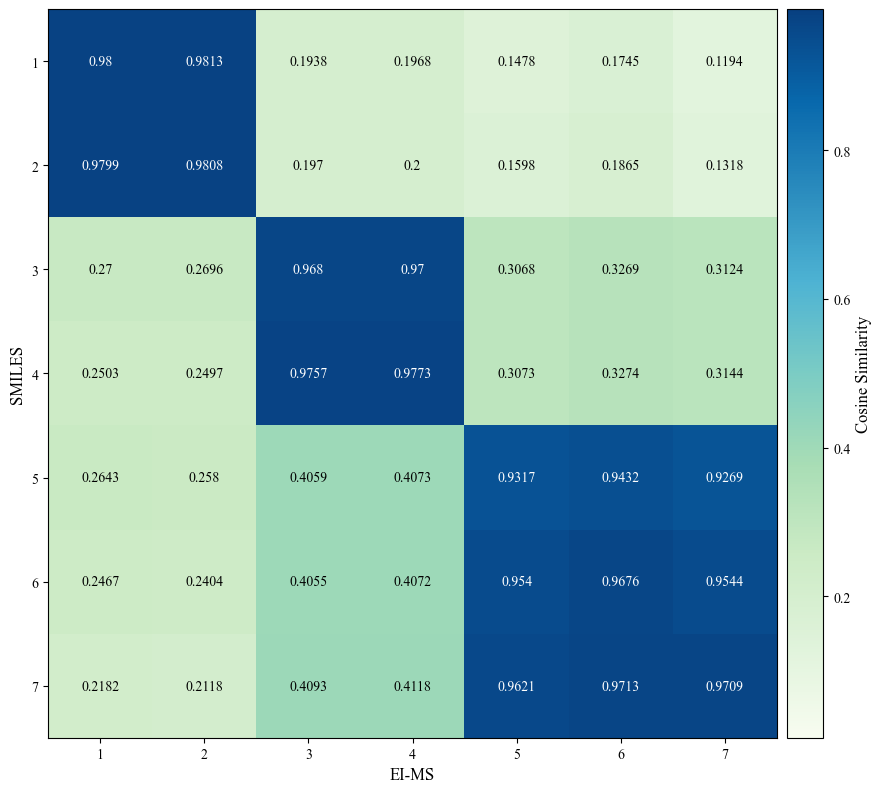

In [ ]:
df = pd.read_csv("data/external_test_dataset/Iso_7/7_smiles_peak_data.csv")
Iso_7_data = (df["smiles"].values.tolist(), df["spectra"].values.tolist()) 
_, all_feature = get_data_and_features(config_path, Iso_7_data, batch_size=1)
smiles_feature, ms_feature, similarity, _, _ = all_feature

fig, ax = plt.subplots(figsize=(10, 10))
im = ax.imshow(similarity, cmap='GnBu', interpolation='nearest')

norm = Normalize(vmin=0.01, vmax=0.99)
im = ax.imshow(similarity, cmap='GnBu', interpolation='nearest', norm=norm)

for i in range(similarity.shape[0]):
    for j in range(similarity.shape[1]):
        color = "white" if similarity[i, j] > 0.5 else "black"
        ax.text(j, i, np.round(similarity[i, j], 4), ha="center", va="center", color=color, fontsize=10)

ax.set_xticks(range(similarity.shape[1]))
ax.set_xticklabels(range(1, similarity.shape[1] + 1))
ax.set_yticks(range(similarity.shape[0]))
ax.set_yticklabels(range(1, similarity.shape[0] + 1))

divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="5%", pad=0.1)
cbar = fig.colorbar(im, cax=cax)
cbar.set_label('Cosine Similarity', fontsize=12)

ax.set_xlabel('EI-MS', fontsize=12)
ax.set_ylabel('SMILES', fontsize=12)

if save_dir is not None:
    save_path = os.path.join(save_dir, 'iso7_cosine_similarity.svg')
    plt.savefig(save_path, bbox_inches="tight", pad_inches=0.02)

plt.show()

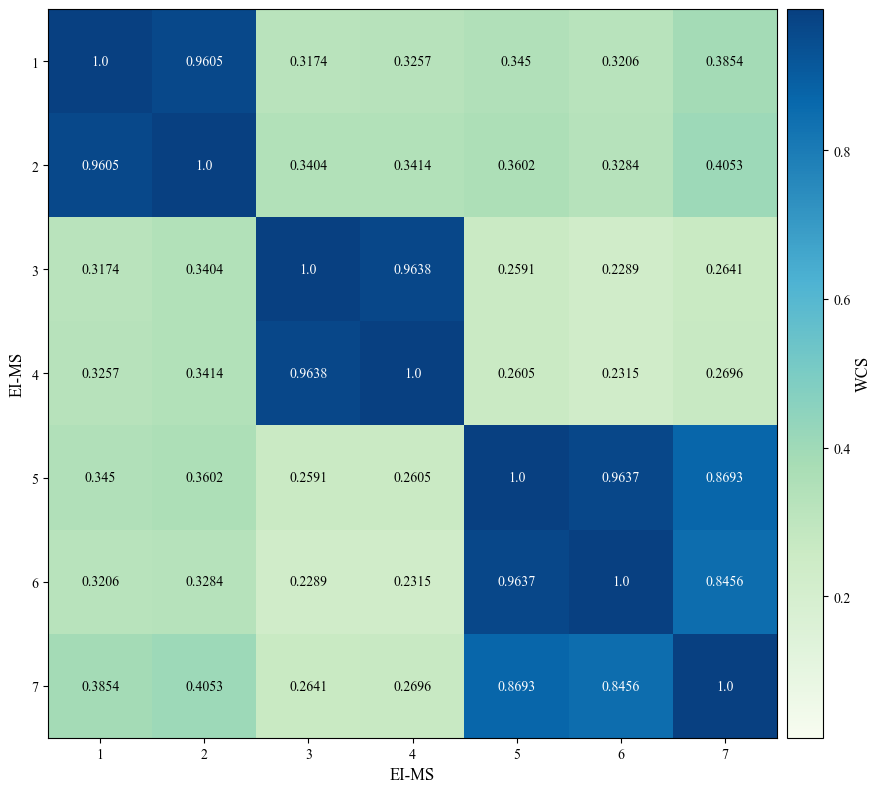

In [11]:
wcs_ms_list = []
for ms in df["spectra"].values.tolist():
    ms_tensor = process_ms_spectra_for_wcs(ms)
    wcs_ms_list.append(ms_tensor)

wcs_ms_tensor = torch.stack(wcs_ms_list) # [7, 1000]
similarity = get_cos_distance(wcs_ms_tensor, wcs_ms_tensor)
similarity = similarity.cpu().numpy()

fig, ax = plt.subplots(figsize=(10, 10))
im = ax.imshow(similarity, cmap='GnBu', interpolation='nearest')
norm = Normalize(vmin=0.01, vmax=0.99)
im = ax.imshow(similarity, cmap='GnBu', interpolation='nearest', norm=norm)


for i in range(similarity.shape[0]):
    for j in range(similarity.shape[1]):
        color = "white" if similarity[i, j] > 0.5 else "black"
        ax.text(j, i, np.round(similarity[i, j], 4), ha="center", va="center", color=color, fontsize=10)


ax.set_xticks(range(similarity.shape[1]))
ax.set_xticklabels(range(1, similarity.shape[1] + 1))
ax.set_yticks(range(similarity.shape[0]))
ax.set_yticklabels(range(1, similarity.shape[0] + 1))

divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="5%", pad=0.1)
cbar = fig.colorbar(im, cax=cax)
cbar.set_label('WCS', fontsize=12)

ax.set_xlabel('EI-MS', fontsize=12)
ax.set_ylabel('EI-MS', fontsize=12)

if save_dir is not None:
    save_path = os.path.join(save_dir, 'iso7_wcs.svg')
    plt.savefig(save_path, bbox_inches="tight", pad_inches=0.02)
plt.show()

# 3. Visualization of Token-Peak Interactions

In [ ]:
from data_provider.dataset import get_tokenined_smiles
df = pd.read_csv("data/external_test_dataset/Gen_10/10_smiles_peak_data.csv")
smile_index = 0
Gen_10_data = ([df["smiles"].values[smile_index]], [df["spectra"].values[smile_index]]) 
preprocessing_data, all_feature = get_data_and_features(config_path, Gen_10_data, batch_size=1)
smiles_ids, smiles_mask, mz, intensity, ms_mask = preprocessing_data
smiles_feature, ms_feature, similarity, smiles_score, ms_score = all_feature
print(similarity)

[[0.98193765]]


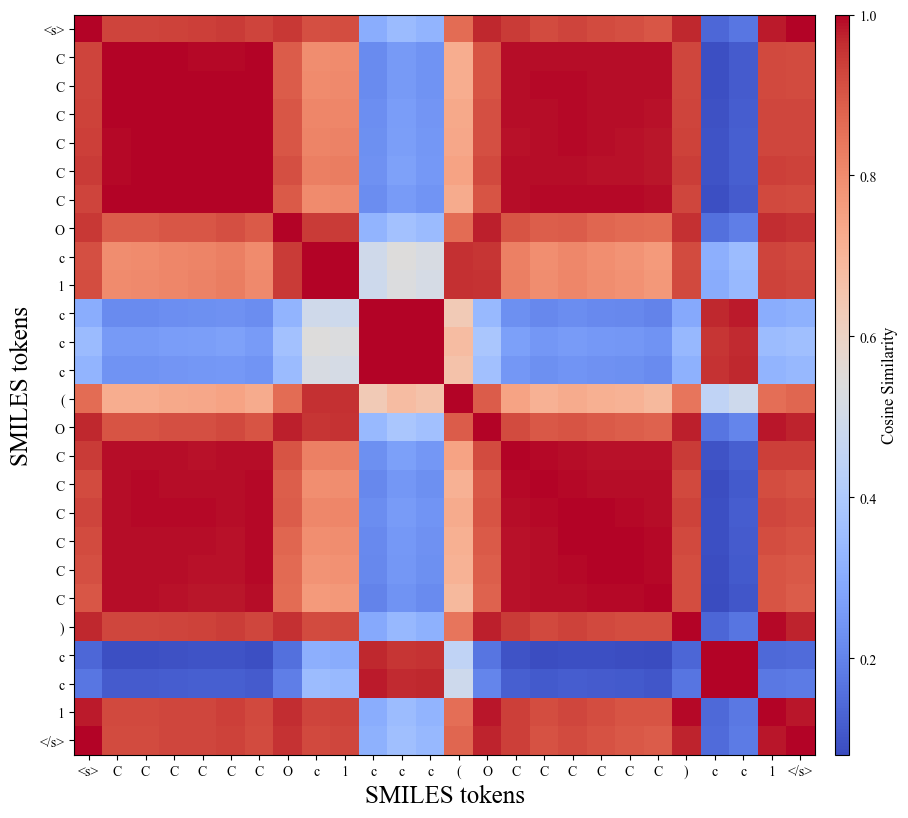

In [ ]:
#  SMILES tokens and SMILES tokens cosine similarity
smi_esa_score = smiles_score[smiles_mask == 1]
smi_esa_score /= torch.norm(smi_esa_score, dim=1, keepdim=True)
token_peak_cos_similarity = smi_esa_score.cpu().numpy() @ smi_esa_score.cpu().numpy().T
smiles_token = get_tokenined_smiles(df["smiles"].values[smile_index], config_path)

plt.figure(figsize=(10, 10))
plt.xticks(range(len(smiles_token)), smiles_token, fontsize=10)
plt.yticks(range(len(smiles_token)), smiles_token, fontsize=10)
plt.xlabel('SMILES tokens', fontsize=18)
plt.ylabel('SMILES tokens', fontsize=18)
ax = plt.gca()
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="2%", pad=0.2)
cbar = plt.colorbar(ax.imshow(token_peak_cos_similarity, cmap='coolwarm', interpolation='nearest'), cax=cax)
cbar.set_label('Cosine Similarity', fontsize=12)

if save_dir is not None:
    save_path = os.path.join(save_dir, 'smiles_token_similarity.svg')
    plt.savefig(save_path, bbox_inches="tight", pad_inches=0.02)
plt.show()

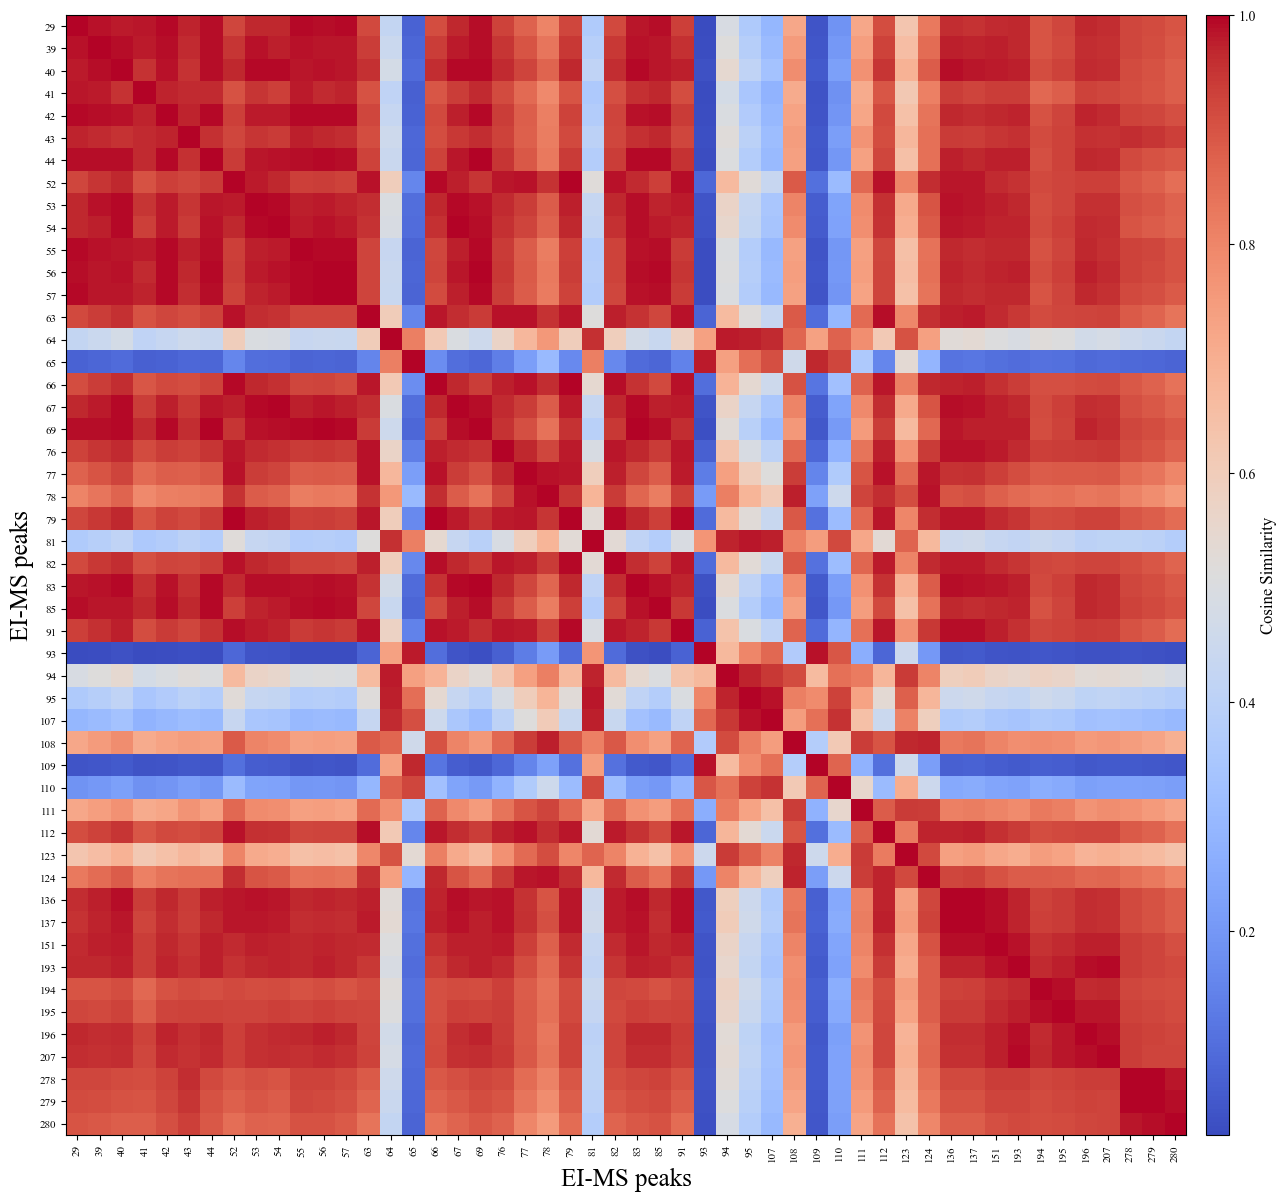

In [ ]:
# EI-MS tokens and EI-MS tokens cosine similarity
mz_np = mz.squeeze(0).cpu().detach().numpy()
mask_cpu = (ms_mask.squeeze(0) == 1).cpu().numpy()
mz = mz_np[mask_cpu]
mz = mz.astype(int)

ms_esa_score = ms_score[ms_mask == 1]
ms_esa_score /= torch.norm(ms_esa_score, dim=1, keepdim=True)
token_peak_cos_similarity = ms_esa_score.cpu().numpy() @ ms_esa_score.cpu().numpy().T

plt.figure(figsize=(15, 15))
plt.xticks(range(len(mz)), mz, fontsize=8, rotation=90)
plt.yticks(range(len(mz)), mz, fontsize=8)
plt.xlabel('EI-MS peaks', fontsize=18)
plt.ylabel('EI-MS peaks', fontsize=18)
ax = plt.gca()
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="2%", pad=0.2)
cbar = plt.colorbar(ax.imshow(token_peak_cos_similarity, cmap='coolwarm', interpolation='nearest'), cax=cax)
cbar.set_label('Cosine Similarity', fontsize=12)

if save_dir is not None:
    save_path = os.path.join(save_dir, 'ms_token_similarity.svg')
    plt.savefig(save_path, bbox_inches="tight", pad_inches=0.02)
plt.show()

[[0.85938203 0.8791617  0.87755054 0.8474995  0.83835    0.8210857 ]]


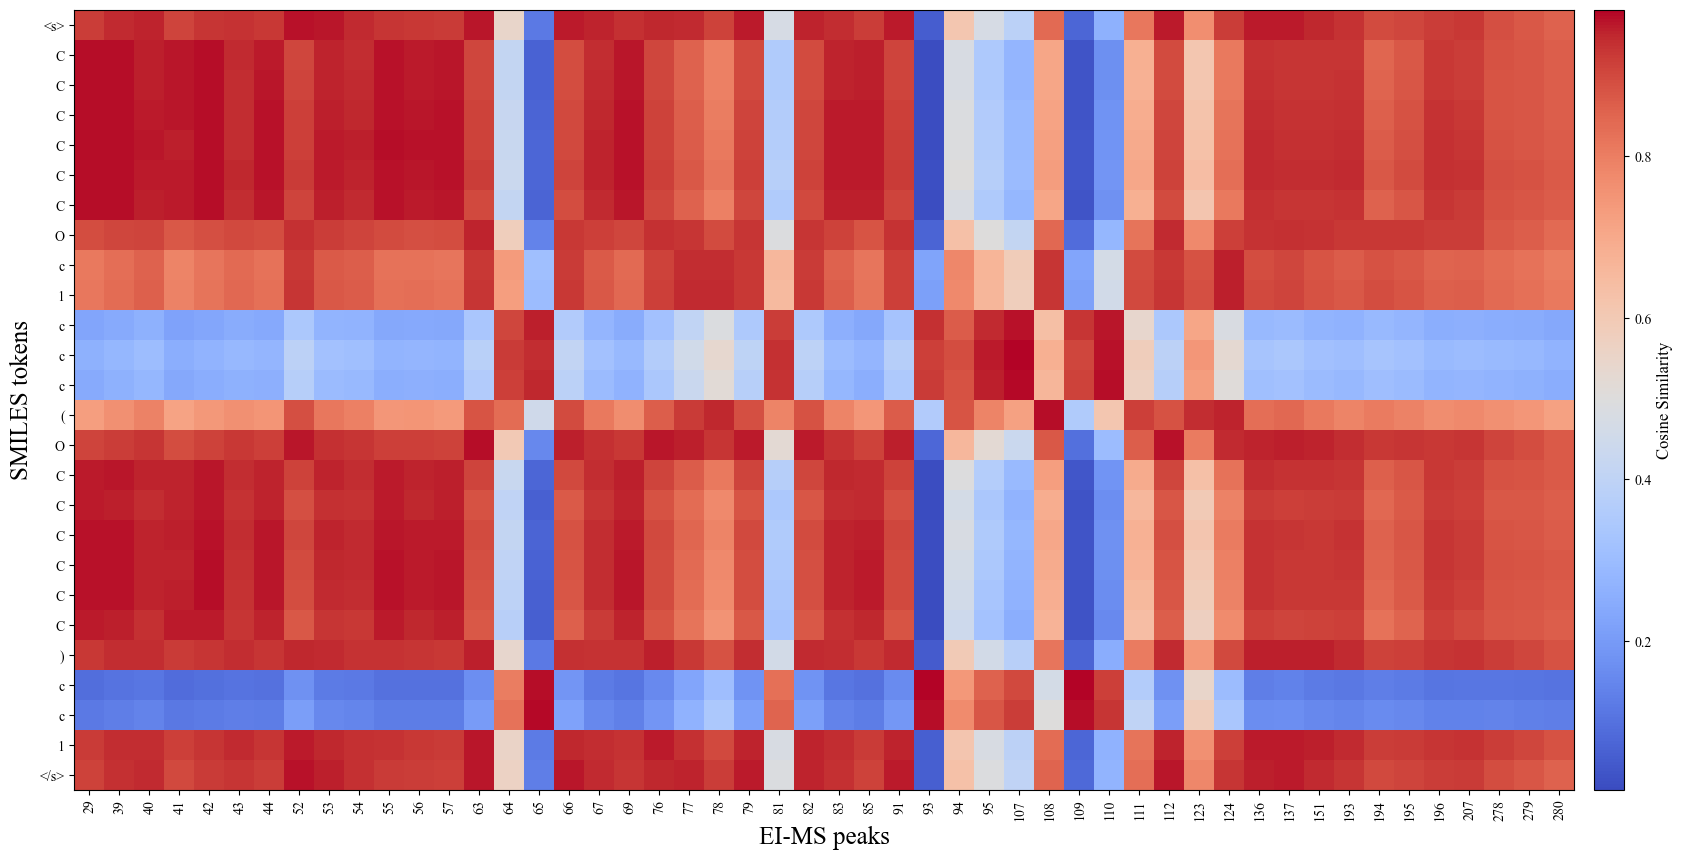

In [ ]:
# SMILES tokens and EI-MS peaks cosine similarity
smi_esa_score = smiles_score[smiles_mask == 1]
ms_esa_score = ms_score[ms_mask == 1]
smi_esa_score /= torch.norm(smi_esa_score, dim=1, keepdim=True)
ms_esa_score /= torch.norm(ms_esa_score, dim=1, keepdim=True)
smiles_feature /= torch.norm(smiles_feature, dim=1, keepdim=True)
token_peak_cos_similarity = smi_esa_score.cpu().numpy() @ ms_esa_score.cpu().numpy().T

max_peak_molecule_similarity =  smiles_feature.cpu().numpy() @ ms_esa_score[-6:].cpu().numpy().T
print(max_peak_molecule_similarity)
plt.figure(figsize=(20, 20))
# plt.imshow(token_peak_cos_similarity, cmap='GnBu', interpolation='nearest') 
# plt.imshow(token_peak_cos_similarity, cmap='coolwarm', interpolation='nearest') 
plt.xticks(range(len(mz)), mz, fontsize=10, rotation=90)
plt.yticks(range(len(smiles_token)), smiles_token, fontsize=10)
# 设置坐标轴标签
plt.xlabel('EI-MS peaks', fontsize=18)
plt.ylabel('SMILES tokens', fontsize=18)

ax = plt.gca()
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="2%", pad=0.2)
cbar = plt.colorbar(ax.imshow(token_peak_cos_similarity, cmap='coolwarm', interpolation='nearest'), cax=cax)
cbar.set_label('Cosine Similarity', fontsize=12)
if save_dir is not None:
    save_path = os.path.join(save_dir, 'smiles_ms_token_similarity.svg')
    plt.savefig(save_path, bbox_inches="tight", pad_inches=0.02)
plt.show()

# 4. Molecular localization in GC-MS files

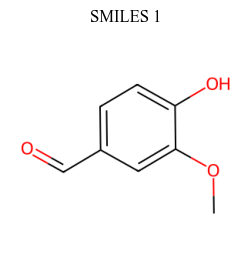

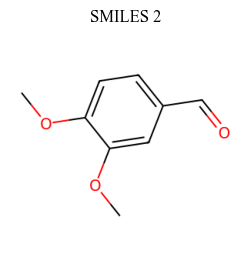

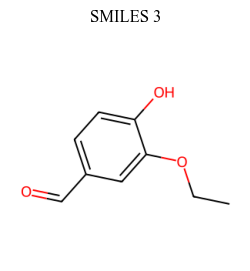

In [ ]:
from utils.NetCDF import data_load, netcdf_reader
filename = 'data/external_test_dataset/xianglansu/250106_Milk_Vanillin.CDF'
X, mz, rt = data_load(filename)
num_ms, num_mz = X.shape
mz = np.tile(mz, (num_ms, 1))
set1_mass_data = np.dstack((mz, X))

with open("data/external_test_dataset/xianglansu/smiles_ms.json", 'r') as f:
    datas = json.loads(f.read())
smiles_list = []
nist_ms_list = []
for data in datas:
    nist_ms_list.append(data["peaks"])
    smiles_list.append(data["smiles"])

# === GC-MS Data Preprocessing: Mass Filtering ===
# Purpose: Filter out high m/z fragments that exceed the target molecular weight (e.g., Vanillin MW ~152.15).
# Why we do this: These larger fragments typically originate from background noise, column bleed, or sample matrix interference. 
# Removing them effectively reduces false signals, improving the accuracy of downstream spectral matching and model retrieval.
MAX_MZ_THRESHOLD = 152.15 
# Simplify logic using NumPy boolean masking: efficiently keep only m/z <= threshold for each scan
filtered_set1_data = [scan[scan[:, 0] <= MAX_MZ_THRESHOLD].tolist() for scan in set1_mass_data]

plot_mol_structure(smiles_list)

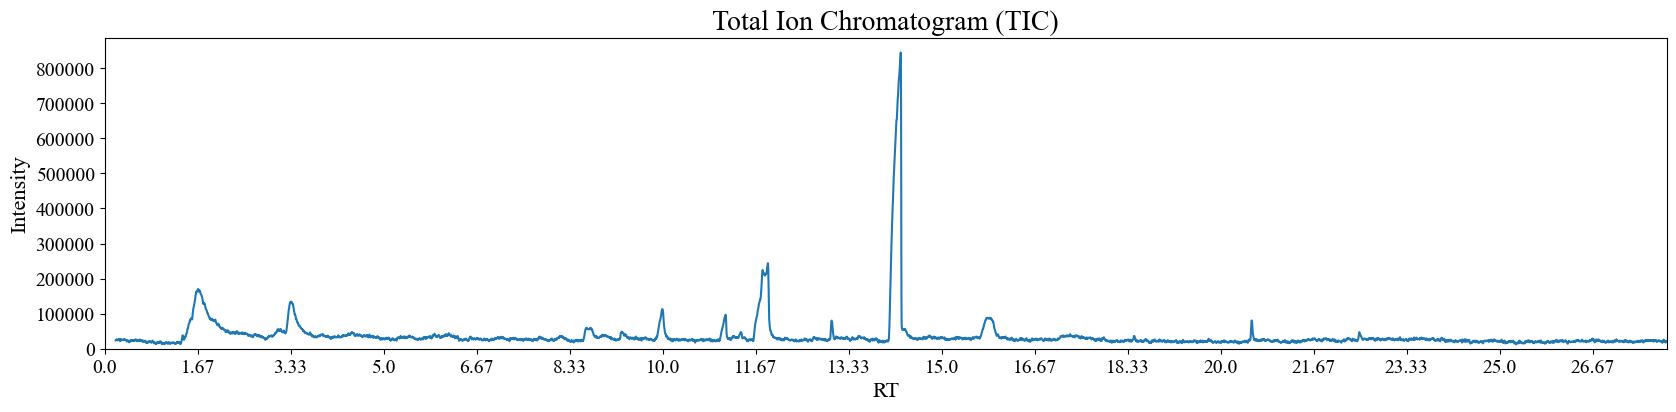

In [16]:
from matplotlib.ticker import MultipleLocator

ncr = netcdf_reader(filename, bmmap=True)
tic_data = ncr.tic()
rt_full = tic_data['rt']
int_full = tic_data['intensity']

rt_cut = 0.2
mask = rt_full >= rt_cut
rt_filtered = rt_full[mask]
int_filtered = int_full[mask]

fig, ax = plt.subplots(figsize=(20, 4))
ax.plot(rt_filtered, int_filtered)

ax.get_yaxis().get_major_formatter().set_scientific(False)
y_major_locator = MultipleLocator(100000)
ax.yaxis.set_major_locator(y_major_locator)

ax.set_xlabel('RT', fontsize=16)
ax.set_ylabel('Intensity', fontsize=16)
ax.set_title('Total Ion Chromatogram (TIC)', fontsize=20)

ax.set_xlim(left=0, right=rt_full.max())
ax.set_ylim(bottom=0)

tick_pos_idx = np.arange(0, len(rt), step=500)
ax.set_xticks(ticks=rt[tick_pos_idx])
ax.set_xticklabels(labels=np.round(rt[tick_pos_idx], 2), fontsize=14)
ax.tick_params(axis='y', labelsize=14)

ax.set_position([0.0625, 0.1366, 0.7812, 0.7768])

if save_dir is not None:
    save_path = os.path.join(save_dir, 'molecular_localization_tic.svg')
    plt.savefig(save_path, bbox_inches="tight", pad_inches=0.02)

plt.show()

## 4.1 EI-MS WCS match

[0.9739492  0.38748905 0.4971105 ]
14.1167(0.9739)
16.5333(0.3875)
20.8900(0.4971)

==== Heatmap Ax Bounding Box ====
x0(left): 0.0625, y0(bottom): 0.1366
x1(right): 0.8437, y1(top): 0.9133
width = 0.7812, height = 0.7768


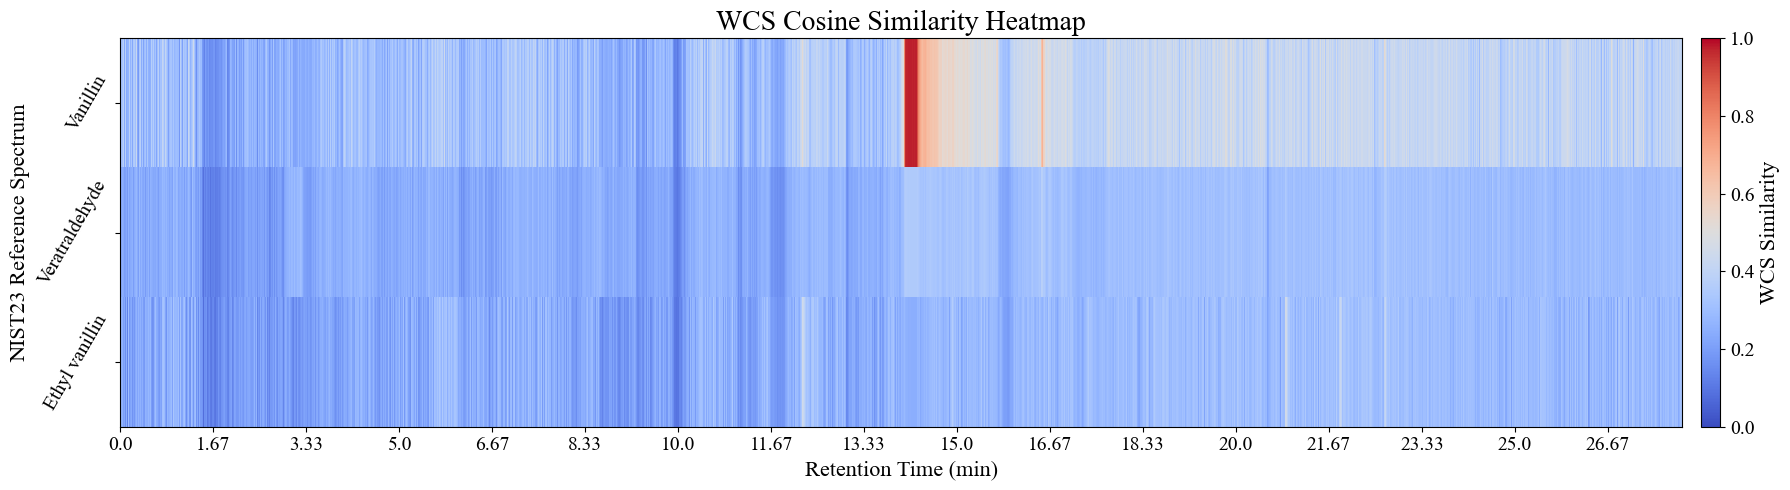

In [13]:
nist_ms_tensor = torch.cat([process_ms_spectra_for_wcs(nist_ms, 1000) for nist_ms in nist_ms_list], dim=0).reshape(-1, 1000)
# set1_ms_tensor = torch.cat([process_ms_spectra_for_wcs(set1_ms, 1000) for set1_ms in set1_mass_data], dim=0).reshape(-1, 1000)
set1_ms_tensor = torch.cat([process_ms_spectra_for_wcs(set1_ms, 1000) for set1_ms in filtered_set1_data], dim=0).reshape(-1, 1000)
nist_ms_tensor /= torch.norm(nist_ms_tensor, dim=-1, keepdim=True)
set1_ms_tensor /= torch.norm(set1_ms_tensor, dim=-1, keepdim=True)
wcs_similarity = nist_ms_tensor @ set1_ms_tensor.T
wcs_similarity[torch.isnan(wcs_similarity)] = 0
wcs_similarity = wcs_similarity.cpu().numpy()
# Print the maximum value of each row, the column index of the maximum value, and retrieve the corresponding RT
max_distance = wcs_similarity.max(axis=1)
print(max_distance)
rt_list = rt[wcs_similarity.argmax(axis=1).tolist()]
result = np.concatenate([np.round(rt_list, 4).reshape(-1, 1), np.round(max_distance, 4).reshape(-1, 1)], axis=1)
for i in range(len(result)):
    print(f"{result[i][0]:.4f}({result[i][1]:.4f})")

# Plot heatmap
name = ['Vanillin', 'Veratraldehyde', 'Ethyl vanillin']
plt.figure(figsize=(20, 5))
# im = plt.imshow(wcs_similarity, aspect='auto', cmap='coolwarm', interpolation='nearest', norm=Normalize(vmin=np.percentile(wcs_similarity, 95), vmax=wcs_similarity.max()))
im = plt.imshow(wcs_similarity, aspect='auto', cmap='coolwarm', interpolation='nearest', norm=Normalize(vmin=0, vmax=1))

cbar = plt.colorbar(im, pad=0.01)
cbar.set_label('WCS Similarity', size=16)
cbar.ax.tick_params(labelsize=14) 

plt.title('WCS Cosine Similarity Heatmap', fontsize=20)
plt.xlabel('Retention Time (min)', fontsize=16)
plt.ylabel('NIST23 Reference Spectrum', fontsize=16)

plt.xticks(
    ticks=np.arange(0, len(rt), step=500), 
    labels=np.round(rt[np.arange(0, len(rt), step=500)], 2),
    fontsize=14
)

plt.yticks(
    ticks=np.arange(0, len(nist_ms_list), step=1), 
    labels=name, 
    rotation=60,  
    va='center',   
    fontsize=14   
)

plt.tight_layout()

ax = plt.gca()
bbox = ax.get_position()
print("\n==== Heatmap Ax Bounding Box ====")
print(f"x0(left): {bbox.x0:.4f}, y0(bottom): {bbox.y0:.4f}")
print(f"x1(right): {bbox.x1:.4f}, y1(top): {bbox.y1:.4f}")
print(f"width = {bbox.x1 - bbox.x0:.4f}, height = {bbox.y1 - bbox.y0:.4f}")

if save_dir is not None:
    save_path = os.path.join(save_dir, 'molecular_localization_wcs.svg')
    plt.savefig(save_path, bbox_inches="tight", pad_inches=0.02)

plt.show()

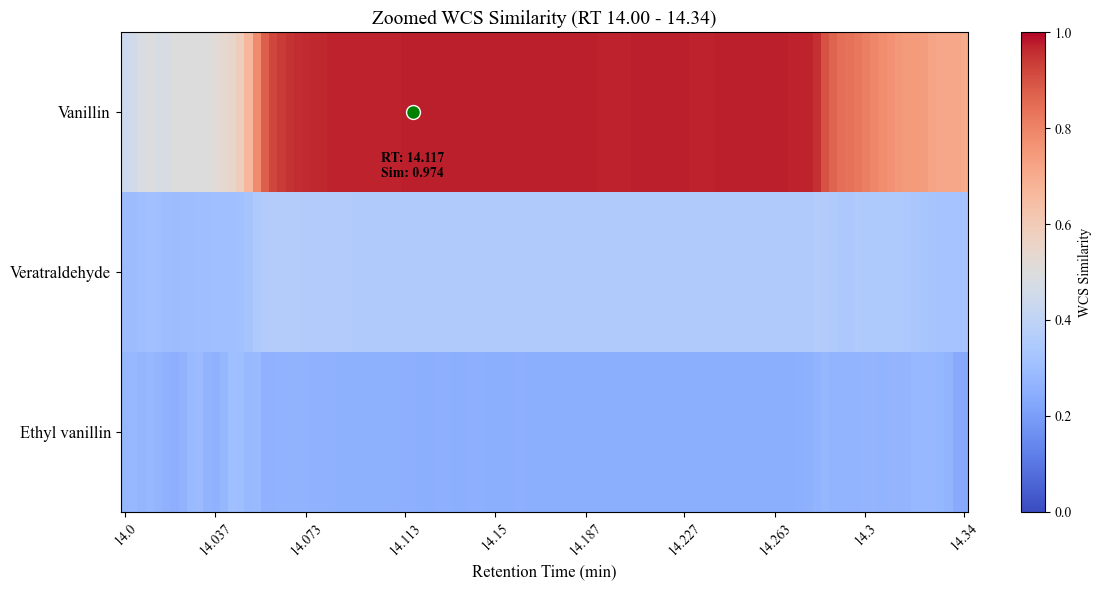

In [14]:
# 1. Automatically determine zoom range: extend 0.15 min before and after the RT of the best matching point
# zoom_start, zoom_end = 14.050, 14.285
zoom_start, zoom_end =  14.00, 14.34
mask = (rt >= zoom_start) & (rt <= zoom_end)

if not mask.any():
    print(f"Warning: No data found in range RT {zoom_start}-{zoom_end}")
else:
    # 2. Prepare sliced data
    sub_sim = wcs_similarity[:, mask]
    sub_rt = rt[mask]
    start_global_idx = np.where(mask)[0][0]  # Starting global index corresponding to the current slice

    # 3. Plotting
    fig, ax = plt.subplots(figsize=(12, 6))
    
    # Draw heatmap
    # Keep consistent colormap with full-view plot; aspect='auto' can be used for stretched display
    im = ax.imshow(sub_sim, aspect='auto', cmap='coolwarm', interpolation='nearest',
                   norm=Normalize(vmin=0, vmax=1))

    # 4. Mark peak points (annotate in zoomed view)
    argmax_indices = wcs_similarity.argmax(axis=1) # Global maximum indices
    
    for row_i, (max_global_idx, max_val) in enumerate(zip(argmax_indices, max_distance)):
        # Check whether the maximum index falls within the current mask range
        if mask[max_global_idx]:
            local_idx = max_global_idx - start_global_idx # Convert to local coordinates
            
            # Draw green marker to circle the maximum position
            ax.scatter(local_idx, row_i, c='green', s=100, edgecolors='white', zorder=5, marker='o')
            # Add text annotation for RT and similarity
            ax.text(local_idx, row_i + 0.25, f'RT: {rt[max_global_idx]:.3f}\nSim: {max_val:.3f}', 
                    color='black', ha='center', va='top', fontweight='bold', fontsize=10)

    # 5. Format axes
    # X-axis: Uniformly sample 10 ticks for RT display
    tick_indices = np.linspace(0, len(sub_rt) - 1, 10, dtype=int)
    ax.set_xticks(tick_indices)
    ax.set_xticklabels(np.round(sub_rt[tick_indices], 3), rotation=45)
    ax.set_xlabel('Retention Time (min)', fontsize=12)
    
    # Y-axis: Display molecule names
    ax.set_yticks(range(len(name)))
    ax.set_yticklabels(name, fontsize=12)

    ax.set_title(f'Zoomed WCS Similarity (RT {zoom_start:.2f} - {zoom_end:.2f})', fontsize=14)
    plt.colorbar(im, ax=ax, label='WCS Similarity')
    plt.tight_layout()
    plt.show()

## 4.2 Cross modal location

14.0733(0.9734)
14.1133(0.6852)
14.2800(0.7598)


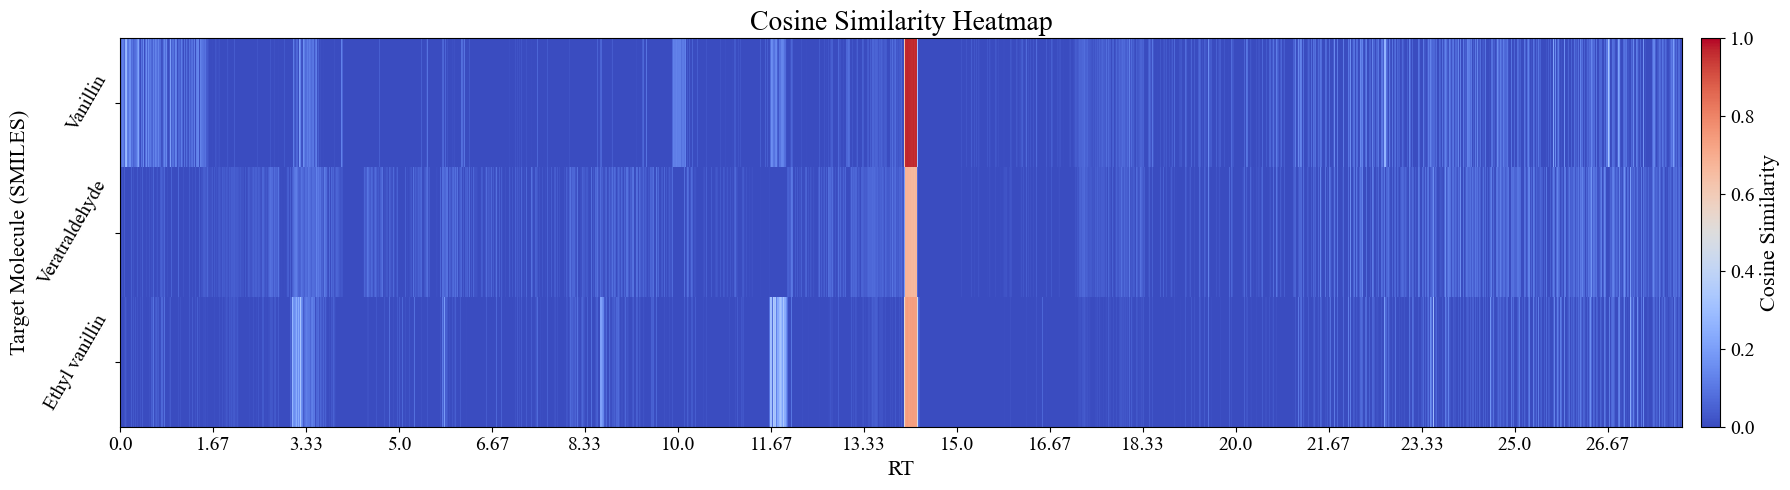

In [15]:
# localization_data = (smiles_list, set1_mass_data.tolist()) 
localization_data = (smiles_list, filtered_set1_data) 
_, all_feature = get_data_and_features(config_path, localization_data, batch_size=128)
smiles_feature, ms_feature, cross_modal_similarity, _, _ = all_feature

cross_modal_similarity[np.isnan(cross_modal_similarity)] = 0
max_distance = cross_modal_similarity.max(axis=1)
argmax_indices = cross_modal_similarity.argmax(axis=1)
rt_list = rt[argmax_indices]
result = np.concatenate([np.round(rt_list, 4).reshape(-1, 1), np.round(max_distance, 4).reshape(-1, 1)], axis=1)
for i in range(len(result)):
    print(f"{result[i][0]:.4f}({result[i][1]:.4f})")

name = ['Vanillin', 'Veratraldehyde', 'Ethyl vanillin']

fig, ax = plt.subplots(figsize=(20, 5))
# im = ax.imshow(cross_modal_similarity, aspect='auto', cmap='viridis', interpolation='nearest', norm=Normalize(vmin=np.percentile(cross_modal_similarity, 95), vmax=cross_modal_similarity.max()))
im = plt.imshow(cross_modal_similarity, aspect='auto', cmap='coolwarm', interpolation='nearest', norm=Normalize(vmin=0, vmax=1))

cbar = plt.colorbar(im, pad=0.01)
cbar.set_label('Cosine Similarity', size=16)
cbar.ax.tick_params(labelsize=14)

plt.title('Cosine Similarity Heatmap', fontsize=20)
plt.xlabel('RT', fontsize=16)
plt.ylabel('Target Molecule (SMILES)', fontsize=16)

# for i in range(len(name)):
#     max_rt_idx = argmax_indices[i]
#     max_sim = max_distance[i]
#     ax.scatter(max_rt_idx, i, color='red', s=100, edgecolors='white', zorder=5)
#     ax.text(max_rt_idx + 50, i, f'RT: {rt[max_rt_idx]:.2f}\nSim: {max_sim:.2f}', color='white', ha='left', va='center', fontsize=10)

plt.xticks(
    ticks=np.arange(0, len(rt), step=500), 
    labels=np.round(rt[np.arange(0, len(rt), step=500)], 2),
    fontsize=14
)

plt.yticks(
    ticks=np.arange(0, len(smiles_list), step=1), 
    labels=name,
    rotation=60,
    va='center',
    fontsize=14
)

plt.tight_layout()
if save_dir is not None:
    save_path = os.path.join(save_dir, 'molecular_localization_cosine_similarity.svg')
    plt.savefig(save_path, bbox_inches="tight", pad_inches=0.02)
plt.show()

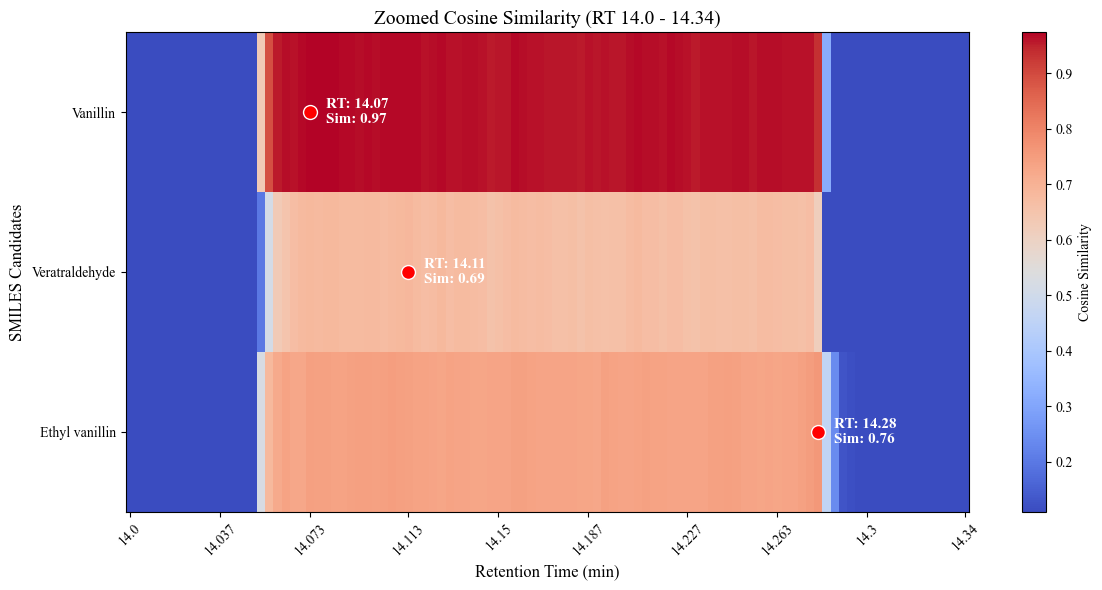

In [ ]:
# 1. Define zoom region (RT range)
if not mask.any():
    print(f"Warning: No data found in range RT {zoom_start}-{zoom_end}")
else:
    # 2. Prepare sliced data
    sub_sim = cross_modal_similarity[:, mask]
    sub_rt = rt[mask]
    start_global_idx = np.where(mask)[0][0]  # Starting global index of current slice

    # 3. Initialize plotting
    fig, ax = plt.subplots(figsize=(12, 6))
    
    # Plot heatmap (use 95th percentile as lower bound to improve contrast)
    vmin, vmax = np.percentile(cross_modal_similarity, 95), cross_modal_similarity.max()
    im = ax.imshow(sub_sim, aspect='auto', cmap='coolwarm', interpolation='nearest',
                   norm=Normalize(vmin=vmin, vmax=vmax))

    # 4. Mark maximum value positions for each row
    for row_i, (max_global_idx, max_val) in enumerate(zip(argmax_indices, max_distance)):
        # Check whether the maximum index falls within the current mask range
        if mask[max_global_idx]:
            local_idx = max_global_idx - start_global_idx # Convert to local coordinate
            
            ax.scatter(local_idx, row_i, c='red', s=100, edgecolors='white', zorder=5)
            ax.text(local_idx + 2, row_i, f'RT: {rt[max_global_idx]:.2f}\nSim: {max_val:.2f}', 
                    color='white', va='center', fontweight='bold', fontsize=11)

    # 5. Format axes
    # X-axis: Uniformly sample 10 points for RT display
    tick_indices = np.linspace(0, len(sub_rt) - 1, 10, dtype=int)
    ax.set_xticks(tick_indices)
    ax.set_xticklabels(np.round(sub_rt[tick_indices], 3), rotation=45)
    ax.set_xlabel('Retention Time (min)', fontsize=12)
    
    # Y-axis: Display molecule names
    ax.set_yticks(range(len(name)))
    ax.set_yticklabels(name, fontsize=10)
    ax.set_ylabel('SMILES Candidates', fontsize=12)

    ax.set_title(f'Zoomed Cosine Similarity (RT {zoom_start} - {zoom_end})', fontsize=14)
    plt.colorbar(im, ax=ax, label='Cosine Similarity')
    plt.tight_layout()
    plt.show()

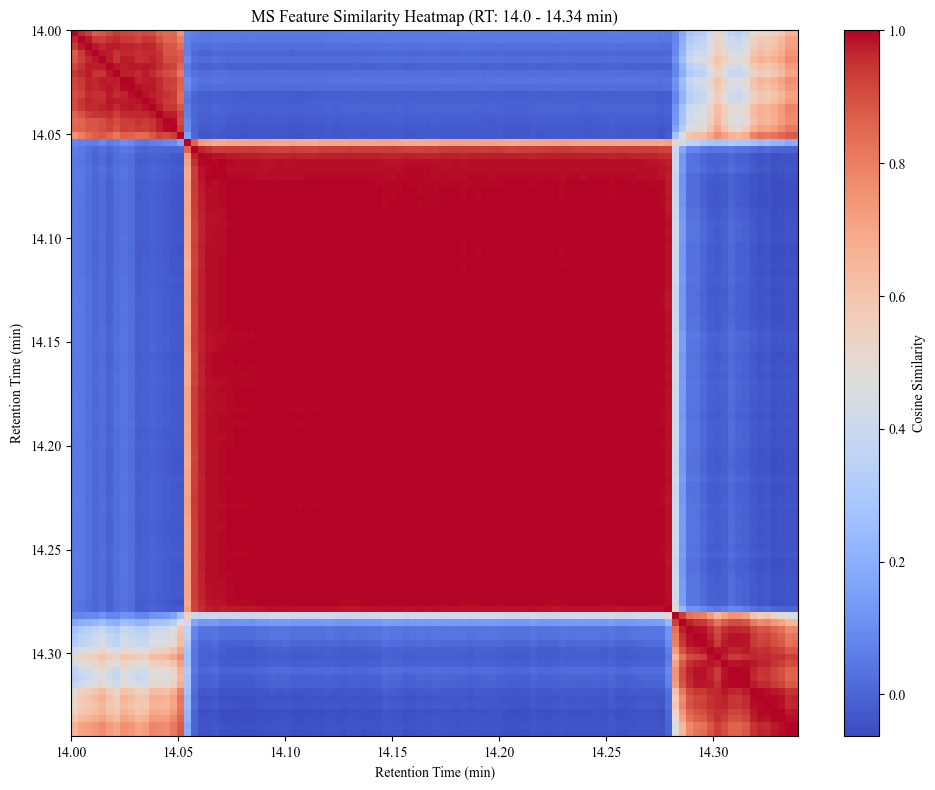

In [ ]:
mask_slice = (rt >= zoom_start) & (rt <= zoom_end)
rt_slice = rt[mask_slice]

if np.sum(mask_slice) == 0:
    print("No data points within the specified range.")
else:
    # Extract corresponding slice of ms_feature
    # Note: Ensure the first dimension of ms_feature matches the length of rt
    if isinstance(ms_feature, torch.Tensor):
        feature_slice = ms_feature[mask_slice]
        # Compute self-similarity (Cosine Similarity)
        # Perform normalization first
        feature_slice_norm = feature_slice / (feature_slice.norm(dim=1, keepdim=True) + 1e-8)
        # Calculate similarity matrix
        similarity_matrix = feature_slice_norm @ feature_slice_norm.T
        similarity_matrix = similarity_matrix.cpu().detach().numpy()
    else:
        # For numpy array input
        feature_slice = ms_feature[mask_slice]
        # Normalization
        norms = np.linalg.norm(feature_slice, axis=1, keepdims=True)
        feature_slice_norm = feature_slice / (norms + 1e-8)
        similarity_matrix = feature_slice_norm @ feature_slice_norm.T

    # Plot heatmap
    plt.figure(figsize=(10, 8))
    # Set axis range to retention time via extent parameter
    # origin='upper' places (0,0) at top-left; cooperate with extent to make Y-axis RT increase from top to bottom
    im = plt.imshow(similarity_matrix, cmap='coolwarm', origin='upper', aspect='auto',
               extent=[rt_slice[0], rt_slice[-1], rt_slice[-1], rt_slice[0]])
    
    plt.colorbar(im, label='Cosine Similarity')
    plt.title(f'MS Feature Similarity Heatmap (RT: {zoom_start} - {zoom_end} min)')
    plt.xlabel('Retention Time (min)')
    plt.ylabel('Retention Time (min)')
    plt.tight_layout()
    plt.show()